In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image


In [2]:
sns.set_theme()
pd.set_option("display.max_colwidth", None)

## Using 30 randomly sampled boxes

In [3]:
EXPERIMENT_FOLDER =  "experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training"

In [4]:
results_random_box_df = pd.read_csv(f"{EXPERIMENT_FOLDER}/results_valid/l2_distance_random_box_30_seeds.csv")


In [5]:
results_random_box_df

,image_name,label,mean_l2_distance,max_l2_distance,box_size,seed
0,00025_99,0,2.182114,4.068795,"(96, 96)",0
1,00100_60,0,2.762097,5.621635,"(96, 96)",0
2,00177_99,0,2.259518,4.727219,"(96, 96)",0
3,00250_60,0,3.643867,6.921415,"(96, 96)",0
4,00303_99,0,3.469232,6.783430,"(96, 96)",0
...,...,...,...,...,...,...
2485,01597_90,1,4.423443,7.047791,"(80, 96)",29
2486,01646_60,1,3.708256,8.806765,"(80, 96)",29
2487,01646_70,1,2.604906,4.519211,"(80, 96)",29
2488,01646_80,1,2.905965,5.949495,"(80, 96)",29



Image: 


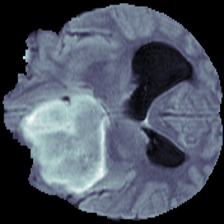


Random box: 


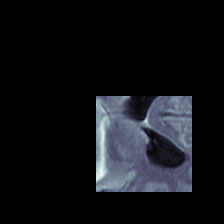


Context: 


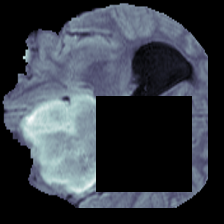

In [7]:
# Example of sampled boxes

image_name = "00134_60"
box_id = 0

print("\nImage: ")
display(Image.open(f"{EXPERIMENT_FOLDER}/results_valid/random_boxes_images/{image_name}_image.png"))
print("\nRandom box: ")
display(Image.open(f"{EXPERIMENT_FOLDER}/results_valid/random_boxes_images/{image_name}_random_pixels_mask_image.png"))
print("\nContext: ")
display(Image.open(f"{EXPERIMENT_FOLDER}/results_valid/random_boxes_images/{image_name}_context_image.png"))


In [ ]:
results_random_box_df["mean_l2_distance"]

0       2.182114
1       2.762097
2       2.259518
3       3.643867
4       3.469232
          ...   
2485    4.423443
2486    3.708256
2487    2.604906
2488    2.905965
2489    2.878477
Name: mean_l2_distance, Length: 2490, dtype: float64

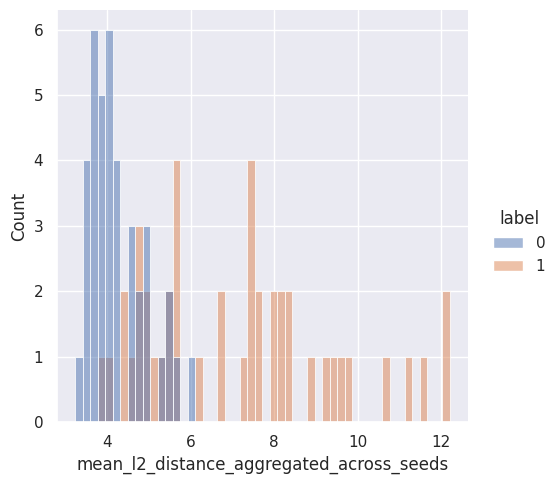

In [61]:
# Results aggregated across different seeds (boxes)

avg_max_distance_per_normal_image = []
avg_max_distance_per_anomaly_image = []

for (image_name, label), image_df in results_random_box_df.groupby(by=["image_name", "label"]):
    avg_per_image = image_df["mean_l2_distance"].max()
    if label == 0:
        avg_max_distance_per_normal_image.append(avg_per_image)
    else:
        avg_max_distance_per_anomaly_image.append(avg_per_image)

agg_df = pd.DataFrame(
    {
        "mean_l2_distance_aggregated_across_seeds": avg_max_distance_per_anomaly_image + avg_max_distance_per_normal_image,
        "label": [1] * len(avg_max_distance_per_anomaly_image) + [0] * len(avg_max_distance_per_normal_image)
    })

sns.set_theme()
sns.displot(agg_df, x="mean_l2_distance_aggregated_across_seeds", hue="label", kind="hist", bins=50)

In [ ]:
print("Anomaly images: mean L2 distance (max patch aggregation per image): ", avg_max_distance_per_anomaly_image)
print("Normal images: mean L2 distance (max patch aggregation per image): ", avg_max_distance_per_normal_image)

sns.set_theme()
sns.displot(results_random_box_df, x="mean_l2_distance", hue="label", kind="hist", bins=200)

Anomaly images: mean L2 distance:  4.513565287806771
Normal images: mean L2 distance:  3.130194081200494


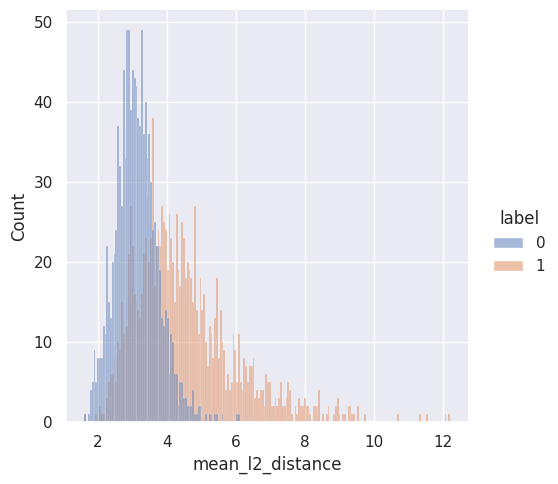

In [54]:
print("Anomaly images: mean L2 distance: ", results_random_box_df[results_random_box_df["label"] == 1]["mean_l2_distance"].mean())
print("Normal images: mean L2 distance: ", results_random_box_df[results_random_box_df["label"] == 0]["mean_l2_distance"].mean())

sns.set_theme()
sns.displot(results_random_box_df, x="mean_l2_distance", hue="label", kind="hist", bins=200)

Anomaly images: max L2 distance:  8.946812313433849
Normal images: max L2 distance:  6.44577344869956


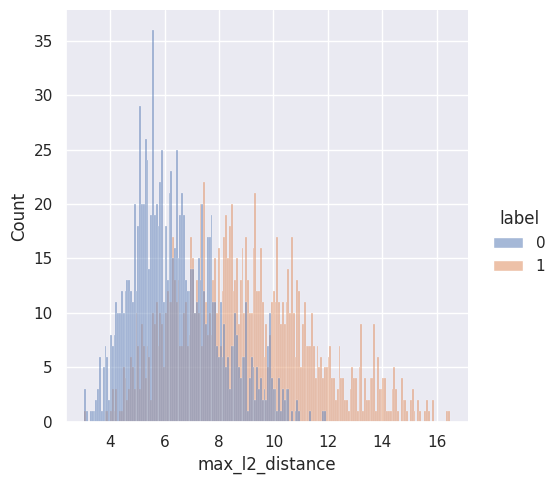

In [53]:
print("Anomaly images: max L2 distance: ", results_random_box_df[results_random_box_df["label"] == 1]["max_l2_distance"].mean())
print("Normal images: max L2 distance: ", results_random_box_df[results_random_box_df["label"] == 0]["max_l2_distance"].mean())

sns.set_theme()
sns.displot(results_random_box_df, x="max_l2_distance", hue="label", kind="hist", bins=200)

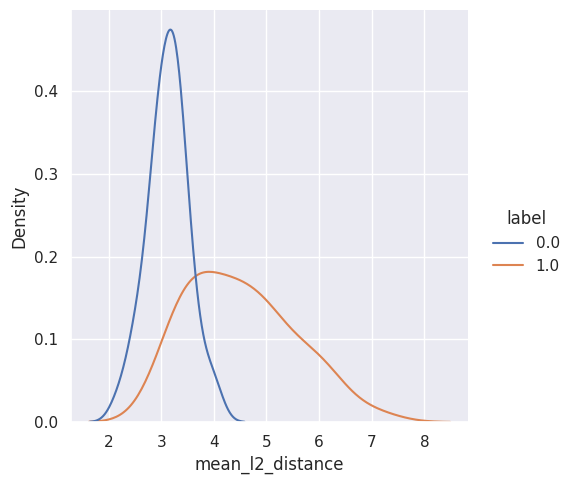

In [11]:
agg_mean = results_random_box_df[['image_name', 'mean_l2_distance', 'label']].groupby('image_name').agg('mean')
sns.displot(data=agg_mean, x="mean_l2_distance", hue='label', kind="kde")

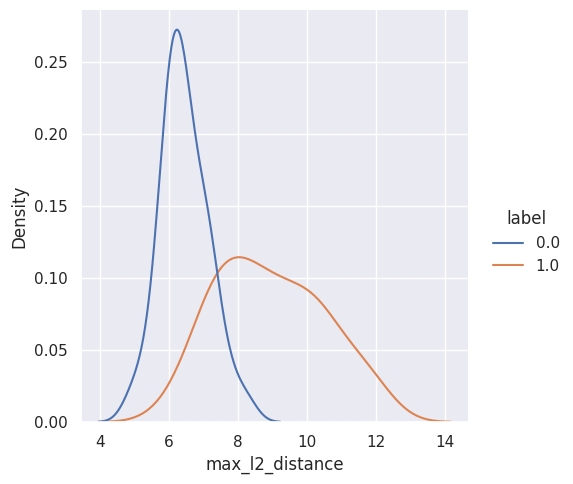

In [12]:
agg_mean = results_random_box_df[['image_name', 'max_l2_distance', 'label']].groupby('image_name').agg('mean')
sns.displot(data=agg_mean, x="max_l2_distance", hue='label', kind="kde")

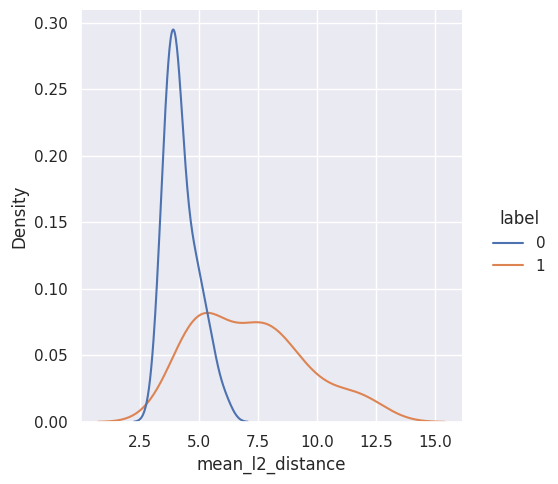

In [13]:
agg_mean = results_random_box_df[['image_name', 'mean_l2_distance', 'label']].groupby('image_name').agg('max')
sns.displot(data=agg_mean, x="mean_l2_distance", hue='label', kind="kde")

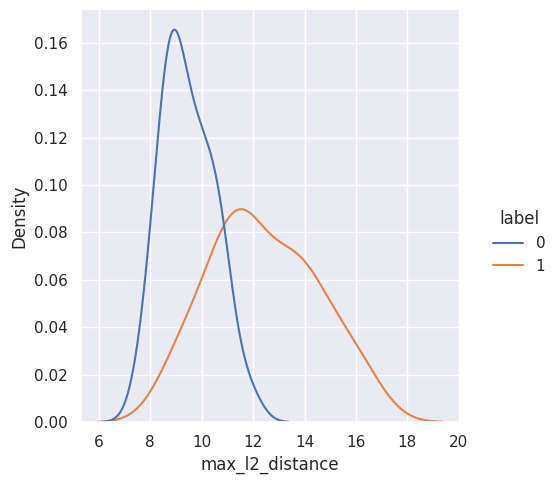

In [14]:
agg_mean = results_random_box_df[['image_name', 'max_l2_distance', 'label']].groupby('image_name').agg('max')
sns.displot(data=agg_mean, x="max_l2_distance", hue='label', kind="kde")

In [15]:
normal_image_mean_l2_distances_per_num_random_boxes = {}
anomaly_image_mean_l2_distances_per_num_random_boxes = {}

box_numbers = sorted(set(results_random_box_df["seed"].to_list()))

for box_num in box_numbers:
    normal_df = results_random_box_df[
        (results_random_box_df["label"] == 0) & 
        (results_random_box_df["seed"] <= box_num)]
    normal_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = normal_df["mean_l2_distance"].mean()
    
    anomaly_df = results_random_box_df[
        (results_random_box_df["label"] == 1) & 
        (results_random_box_df["seed"] <= box_num)]
    anomaly_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = anomaly_df["mean_l2_distance"].mean()


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Mean L2 distance'),
 Text(0.5, 1.0, 'Normal images')]

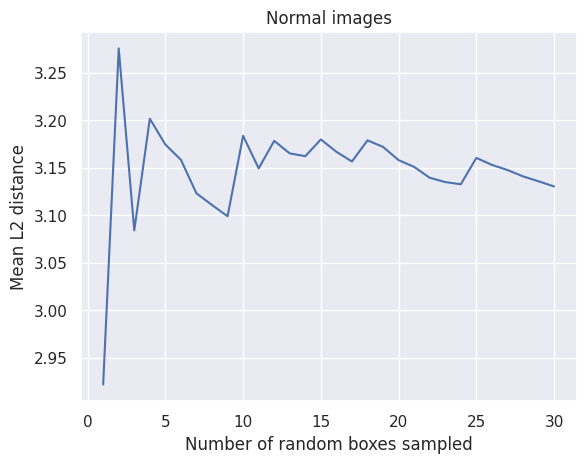

In [16]:
ax = sns.lineplot(x=list(normal_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(normal_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Mean L2 distance', title="Normal images")


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Mean L2 distance'),
 Text(0.5, 1.0, 'Anomaly images')]

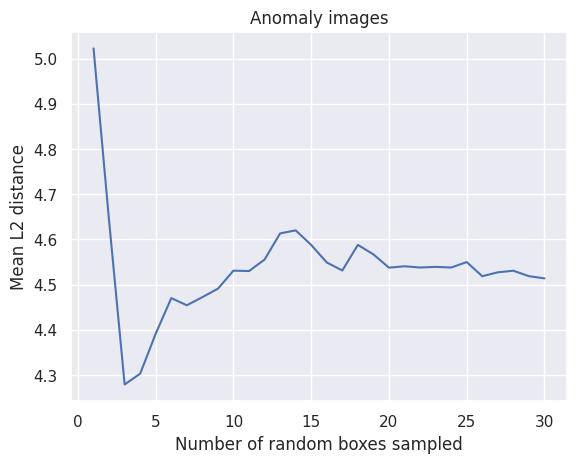

In [17]:
ax = sns.lineplot(x=list(anomaly_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(anomaly_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Mean L2 distance', title="Anomaly images")

In [18]:
normal_image_mean_l2_distances_per_num_random_boxes = {}
anomaly_image_mean_l2_distances_per_num_random_boxes = {}

box_numbers = sorted(set(results_random_box_df["seed"].to_list()))

for box_num in box_numbers:
    normal_df = results_random_box_df[
        (results_random_box_df["label"] == 0) & 
        (results_random_box_df["seed"] <= box_num)]
    normal_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = normal_df["mean_l2_distance"].max()
    
    anomaly_df = results_random_box_df[
        (results_random_box_df["label"] == 1) & 
        (results_random_box_df["seed"] <= box_num)]
    anomaly_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = anomaly_df["mean_l2_distance"].max()


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Mean L2 distance'),
 Text(0.5, 1.0, 'Normal images')]

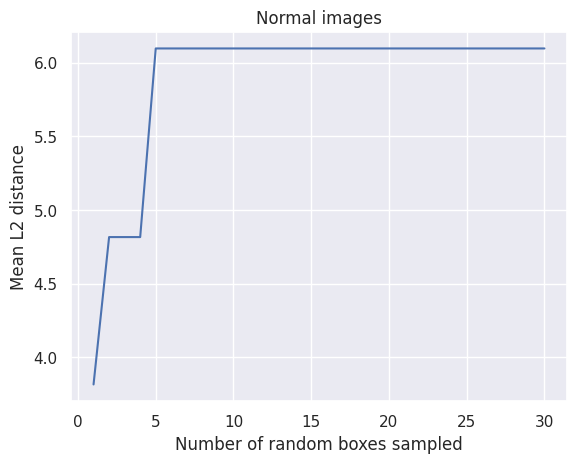

In [19]:
ax = sns.lineplot(x=list(normal_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(normal_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Mean L2 distance', title="Normal images")


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Mean L2 distance'),
 Text(0.5, 1.0, 'Anomaly images')]

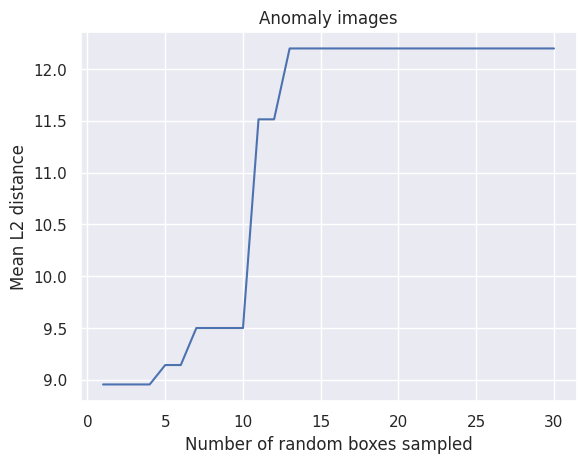

In [20]:
ax = sns.lineplot(x=list(anomaly_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(anomaly_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Mean L2 distance', title="Anomaly images")

In [21]:
normal_image_mean_l2_distances_per_num_random_boxes = {}
anomaly_image_mean_l2_distances_per_num_random_boxes = {}

box_numbers = sorted(set(results_random_box_df["seed"].to_list()))

for box_num in box_numbers:
    normal_df = results_random_box_df[
        (results_random_box_df["label"] == 0) & 
        (results_random_box_df["seed"] <= box_num)]
    normal_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = normal_df["max_l2_distance"].mean()
    
    anomaly_df = results_random_box_df[
        (results_random_box_df["label"] == 1) & 
        (results_random_box_df["seed"] <= box_num)]
    anomaly_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = anomaly_df["max_l2_distance"].mean()


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Max L2 distance'),
 Text(0.5, 1.0, 'Normal images')]

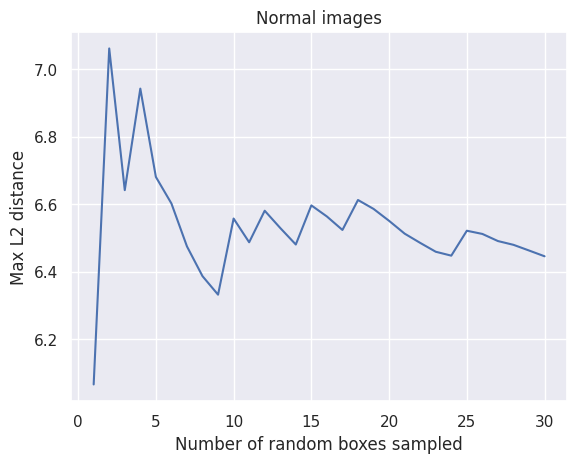

In [22]:
ax = sns.lineplot(x=list(normal_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(normal_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Max L2 distance', title="Normal images")

[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Max L2 distance'),
 Text(0.5, 1.0, 'Anomaly images')]

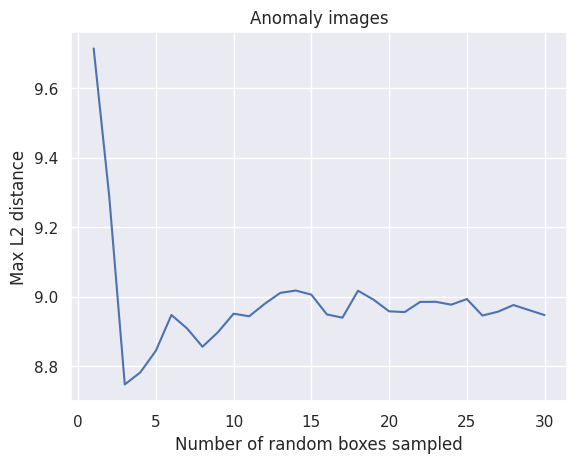

In [23]:
ax = sns.lineplot(x=list(anomaly_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(anomaly_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Max L2 distance', title="Anomaly images")

In [24]:
normal_image_mean_l2_distances_per_num_random_boxes = {}
anomaly_image_mean_l2_distances_per_num_random_boxes = {}

box_numbers = sorted(set(results_random_box_df["seed"].to_list()))

for box_num in box_numbers:
    normal_df = results_random_box_df[
        (results_random_box_df["label"] == 0) & 
        (results_random_box_df["seed"] <= box_num)]
    normal_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = normal_df["max_l2_distance"].max()
    
    anomaly_df = results_random_box_df[
        (results_random_box_df["label"] == 1) & 
        (results_random_box_df["seed"] <= box_num)]
    anomaly_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = anomaly_df["max_l2_distance"].max()


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Max L2 distance'),
 Text(0.5, 1.0, 'Normal images')]

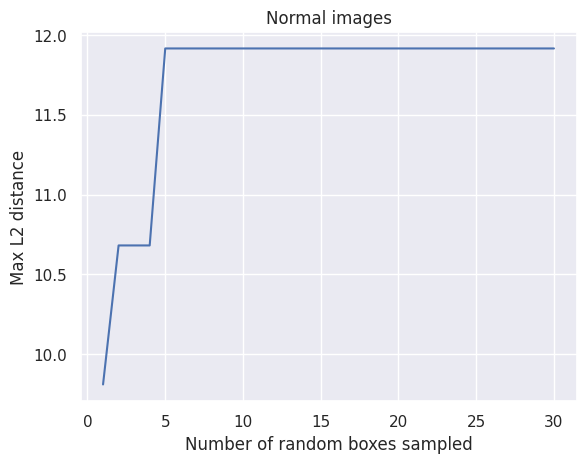

In [25]:
ax = sns.lineplot(x=list(normal_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(normal_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Max L2 distance', title="Normal images")

[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Max L2 distance'),
 Text(0.5, 1.0, 'Anomaly images')]

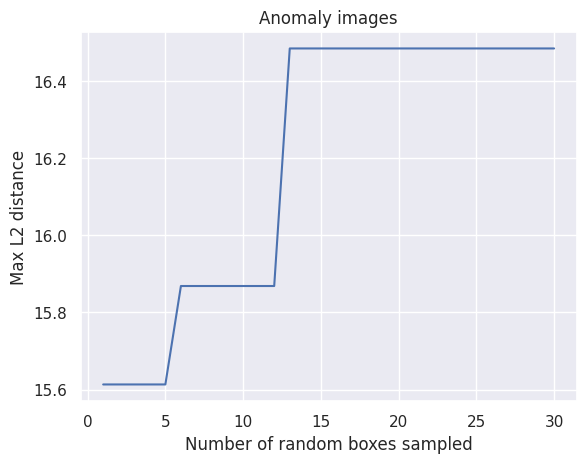

In [26]:
ax = sns.lineplot(x=list(anomaly_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(anomaly_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Max L2 distance', title="Anomaly images")

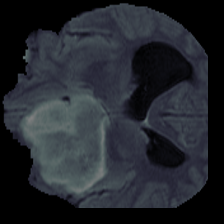

In [28]:
from PIL import Image

# Example of sampled boxes

image_name = "00134_60"
box_id = 0

original_image = Image.open(f"{EXPERIMENT_FOLDER}/results_valid/random_boxes_images/{image_name}_image.png")
box = Image.open(f"{EXPERIMENT_FOLDER}/results_valid/random_boxes_images/{image_name}_random_pixels_mask_image.png")
context = Image.open(f"{EXPERIMENT_FOLDER}/results_valid/random_boxes_images/{image_name}_context_image.png")

Image.blend(context, box, alpha=0.5)

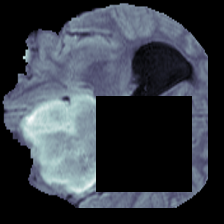

In [29]:
context

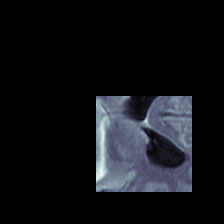

In [30]:
box

In [31]:
import glob
import os
import pandas as pd

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_colwidth', 500)


metric_file_paths = glob.glob(os.path.join(
    "experiments_*/*/**/",
    "*.csv"), recursive=True)

filtered_metric_file_paths = [metric_file_path for metric_file_path in metric_file_paths
                               if "Metrics" in metric_file_path]




In [32]:
metrics_dfs = []
for filtered_metric_file_path in filtered_metric_file_paths:
    metrics_dfs.append(pd.read_csv(filtered_metric_file_path))
concat_metrics_df = pd.concat(metrics_dfs).reset_index(drop=True)

In [33]:
concat_metrics_df["Avg(Image ROCAUC, Pixel ROCAUC)"] = concat_metrics_df.apply(lambda x: (x["Image ROCAUC"] + x["Pixel ROCAUC"]) / 2.0, axis=1)

In [34]:
brain_valid_df = concat_metrics_df[
    (concat_metrics_df["SPLIT"] == "valid") & ((concat_metrics_df["DATASET_NAME"] == "BraTS2021_slice"))].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False)

brain_valid_df

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,"Avg(Image ROCAUC, Pixel ROCAUC)"
5,BraTS2021_slice,valid,mean,30,4,max,0.952797,0.978260,l2,0.5,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training,0.965528
3,BraTS2021_slice,valid,mean,30,4,max,0.930653,0.975629,l2,0.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training,0.953141
4,BraTS2021_slice,valid,mean,30,4,max,0.820513,0.961480,l2,1.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training,0.890996


In [35]:
valid_df = concat_metrics_df[
    (concat_metrics_df["SPLIT"] == "valid") & ((concat_metrics_df["DATASET_NAME"] == "RESC"))].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False)

In [36]:
valid_df

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,"Avg(Image ROCAUC, Pixel ROCAUC)"


In [39]:
concat_metrics_df[
    (concat_metrics_df["SPLIT"] == "test") & ((concat_metrics_df["DATASET_NAME"] == "BraTS2021_slice"))].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False)

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,"Avg(Image ROCAUC, Pixel ROCAUC)"
2,BraTS2021_slice,test,mean,30,4,max,0.927503,0.973062,l2,0.5,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training,0.950283
0,BraTS2021_slice,test,mean,30,4,max,0.893372,0.969366,l2,0.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training,0.931369
1,BraTS2021_slice,test,mean,30,4,max,0.822896,0.955194,l2,1.0,enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3_cropped_random_crop_training,0.889045


In [40]:
concat_metrics_df[
    (concat_metrics_df["SPLIT"] == "valid") & ((concat_metrics_df["DATASET_NAME"] == "RESC"))].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False)

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,"Avg(Image ROCAUC, Pixel ROCAUC)"


### Sigma hyperparameter (Gaussian blurring filter) impact

### 3 random boxes sampled

In [41]:
concat_metrics_df[(concat_metrics_df["SPLIT"] == "valid") &\
                   (concat_metrics_df["NUM_TARGET_BOXES_PER_IMAGE"] == 3) &\
                   (concat_metrics_df["AGGREGATE_PATCHES_STRATEGY"] == "mean") &\
                   (concat_metrics_df["PER_IMAGE_STATISTIC"] == "mean")]\
    .sort_values(by=["Image ROCAUC", "Pixel ROCAUC"] , ascending=False)

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,"Avg(Image ROCAUC, Pixel ROCAUC)"


In [42]:
concat_metrics_df[(concat_metrics_df["SPLIT"] == "valid") &\
                   (concat_metrics_df["NUM_TARGET_BOXES_PER_IMAGE"] == 30) &\
                   (concat_metrics_df["AGGREGATE_PATCHES_STRATEGY"] == "max") &\
                   (concat_metrics_df["PER_IMAGE_STATISTIC"] == "mean") &\
                   (concat_metrics_df["EXPERIMENT_NAME"].isna()) &\
                   (concat_metrics_df["DATASET_NAME"] == "BraTS2021_slice")]\
    .sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False).reset_index(drop=True)

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,"Avg(Image ROCAUC, Pixel ROCAUC)"


### 30 random boxes sampled

In [47]:
concat_metrics_df[(concat_metrics_df["SPLIT"] == "valid") &\
                   (concat_metrics_df["NUM_TARGET_BOXES_PER_IMAGE"] == 3) &\
                   (concat_metrics_df["AGGREGATE_PATCHES_STRATEGY"] == "mean") &\
                   (concat_metrics_df["PER_IMAGE_STATISTIC"] == "mean") &\
                   (concat_metrics_df["EXPERIMENT_NAME"].isna()) &\
                   (concat_metrics_df["GAUSSIAN_FILTER_BLUR_SIGMA"].isin([-1, 1, 2, 3, 4, 5])) &\
                   (concat_metrics_df["DATASET_NAME"] == "BraTS2021_slice") &\
                   (concat_metrics_df["DISTANCE"] == "l2")
                   ].sort_values(by=["Avg(Image ROCAUC, Pixel ROCAUC)"] , ascending=False).reset_index(drop=True)

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,"Avg(Image ROCAUC, Pixel ROCAUC)"


In [48]:
concat_metrics_df[(concat_metrics_df["NUM_TARGET_BOXES_PER_IMAGE"] == 30) & 
         (concat_metrics_df["EXPERIMENT_NAME"].isna()) &
         (concat_metrics_df["GAUSSIAN_FILTER_BLUR_SIGMA"] == 4) &
         (concat_metrics_df["DISTANCE"] == "l1") &
         (concat_metrics_df["AGGREGATE_PATCHES_STRATEGY"] == "max") &
         (concat_metrics_df["PER_IMAGE_STATISTIC"] == "mean")
].reset_index(drop=True)

,DATASET_NAME,SPLIT,AGGREGATE_PATCHES_STRATEGY,NUM_TARGET_BOXES_PER_IMAGE,GAUSSIAN_FILTER_BLUR_SIGMA,PER_IMAGE_STATISTIC,Image ROCAUC,Pixel ROCAUC,DISTANCE,WEIGHT_DISTILLATION,EXPERIMENT_NAME,"Avg(Image ROCAUC, Pixel ROCAUC)"


## RESC dataset results